# 02 · Exploratory Data Analysis

Explores the cleaned **training set only**, so nothing seen here can influence decisions about the test data.

## 1. Imports and plot style

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams['font.size'] = 11

## 2. Load data

In [5]:
df = pd.read_csv('../data/borrower_clean_train.csv')

print("Shape:", df.shape)
print("Nulls:", df.isnull().sum().sum(), "(these are the _raw EXT_SOURCE columns, kept with real gaps on purpose)")
print("Columns:", df.columns.tolist())

Shape: (215257, 24)
Nulls: 164608 (these are the _raw EXT_SOURCE columns, kept with real gaps on purpose)
Columns: ['SK_ID_CURR', 'TARGET', 'age_years', 'employment_years', 'annual_income', 'loan_amount', 'annual_repayment', 'debt_to_income', 'repayment_burden', 'gender', 'employment_type', 'education', 'family_status', 'owns_car', 'owns_property', 'num_children', 'region_risk_rating', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'EXT_SOURCE_1_raw', 'EXT_SOURCE_2_raw', 'EXT_SOURCE_3_raw', 'not_employed_flag']


## 3. Target distribution

Only about 8% of borrowers default. This imbalance is why the project uses stratified splits, class weighting and ROC-AUC / PR-AUC instead of accuracy.

TARGET
0    197880
1     17377
Name: count, dtype: int64
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


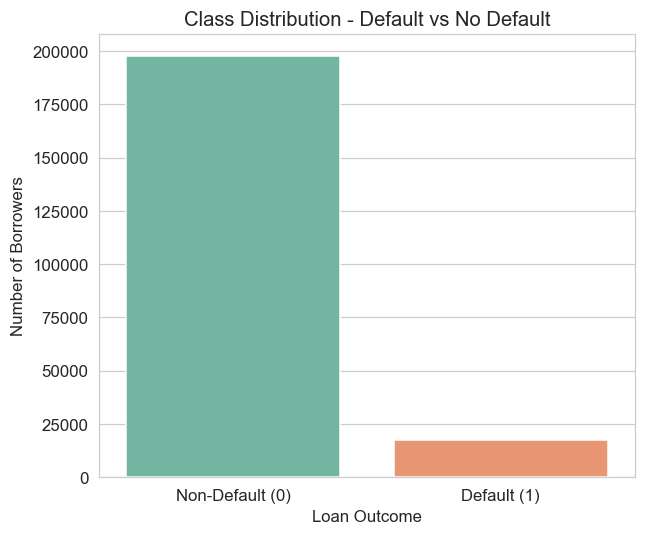

In [7]:
print(df['TARGET'].value_counts())
print(round(df['TARGET'].value_counts(normalize=True) * 100, 2))

plt.figure(figsize=(6, 5))
sns.countplot(data=df, x='TARGET', hue='TARGET', palette='Set2', legend=False)
plt.title("Class Distribution - Default vs No Default")
plt.xlabel("Loan Outcome")
plt.ylabel("Number of Borrowers")
plt.xticks([0, 1], ["Non-Default (0)", "Default (1)"])
plt.tight_layout()
plt.show()

## 4. Numerical distributions

Note the tall spikes in EXT_SOURCE_1 and employment_years: these are created by median imputation in notebook 01.

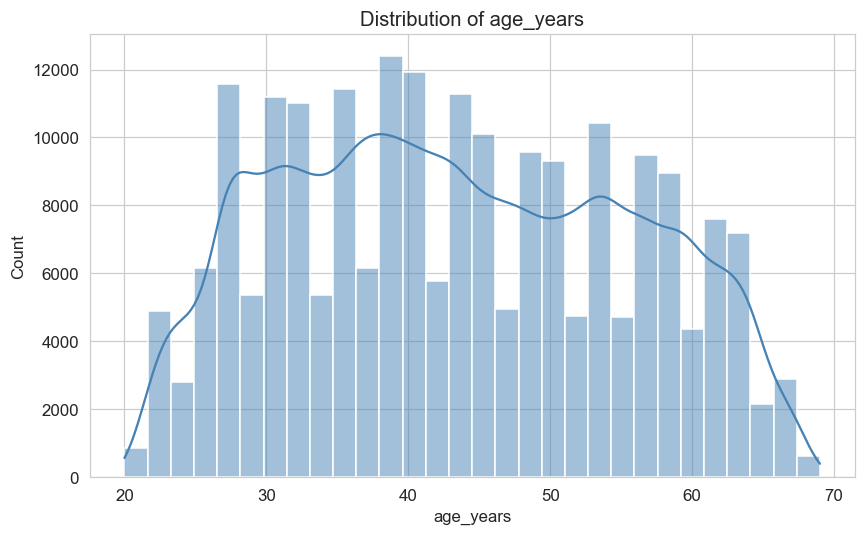

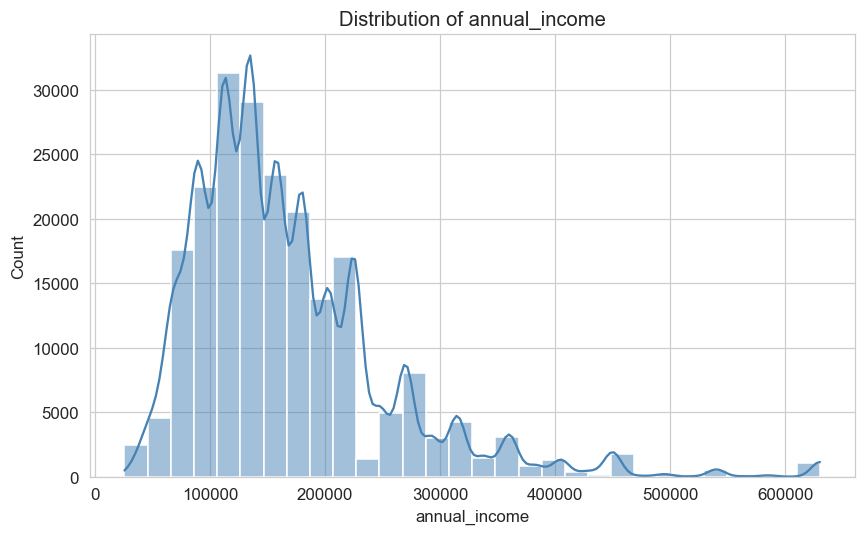

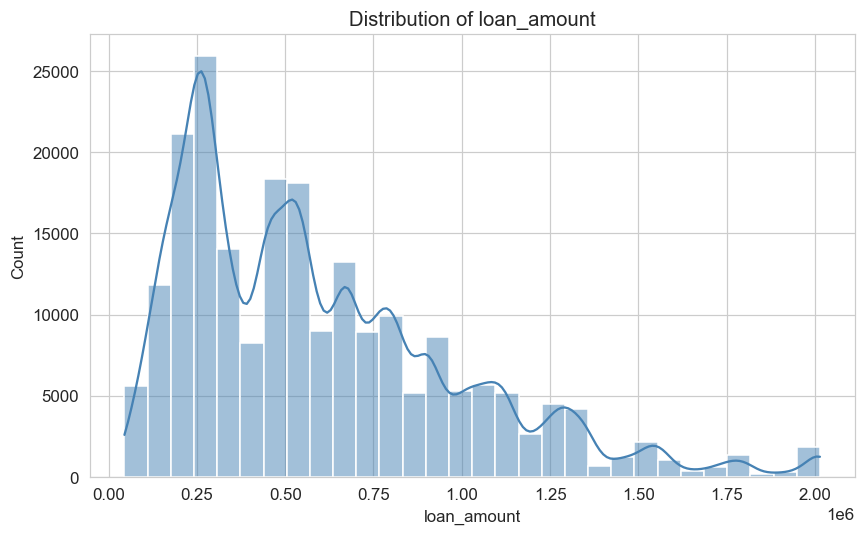

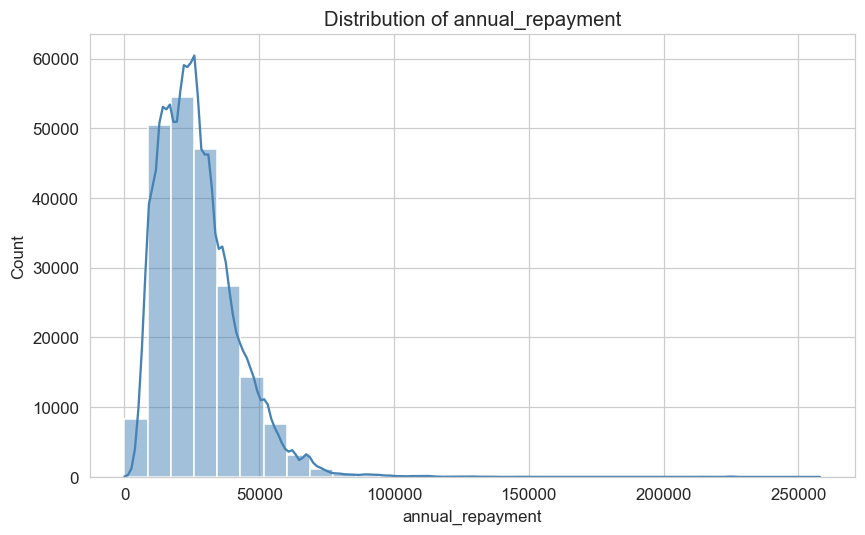

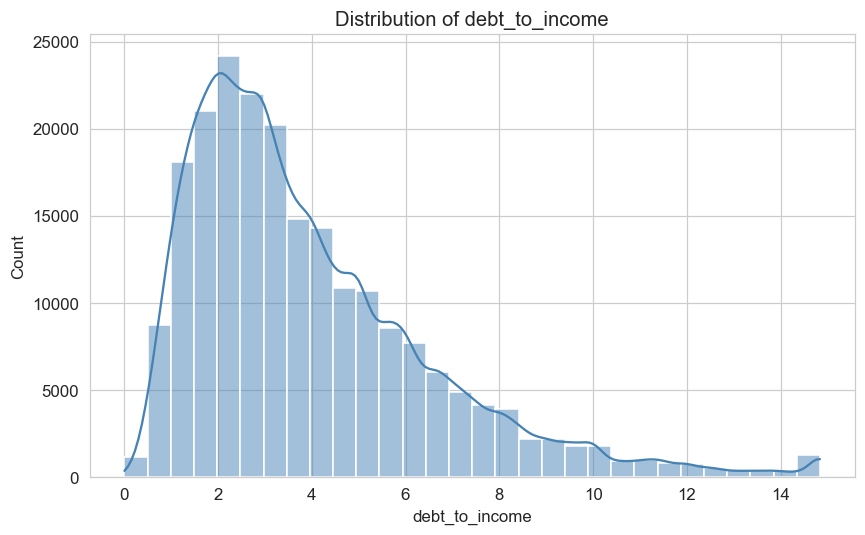

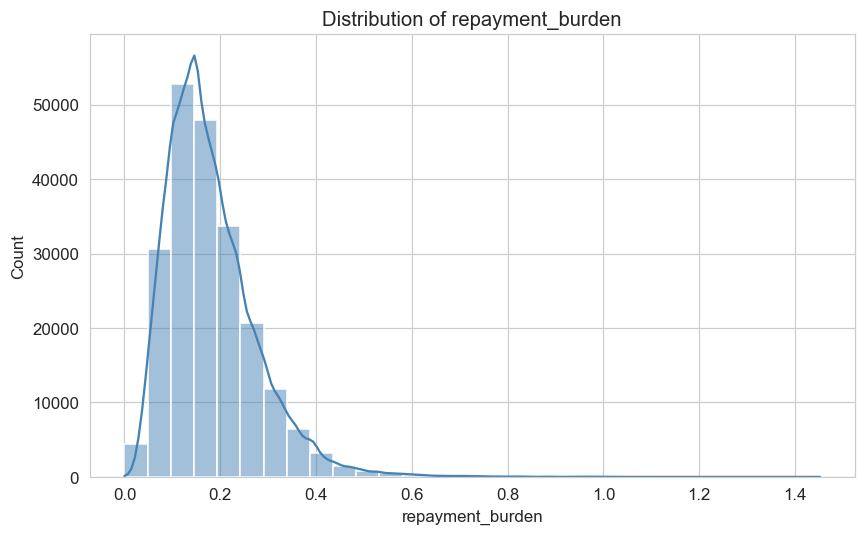

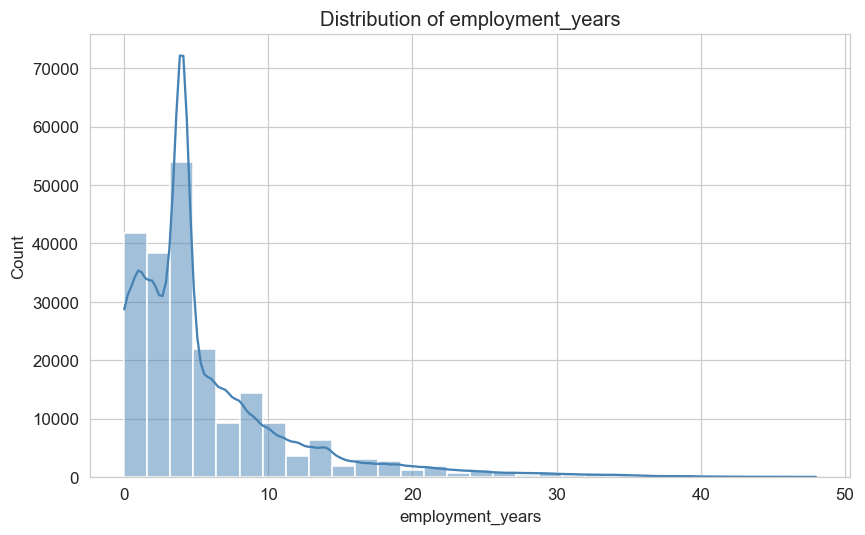

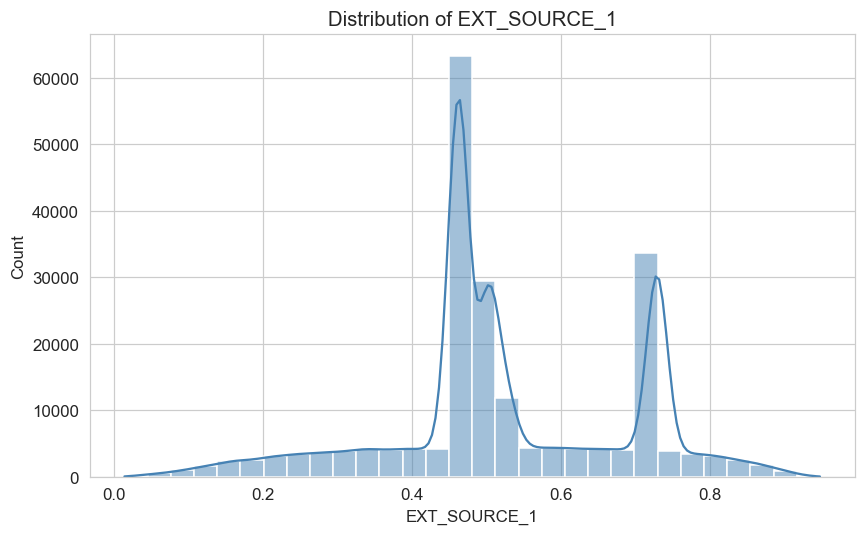

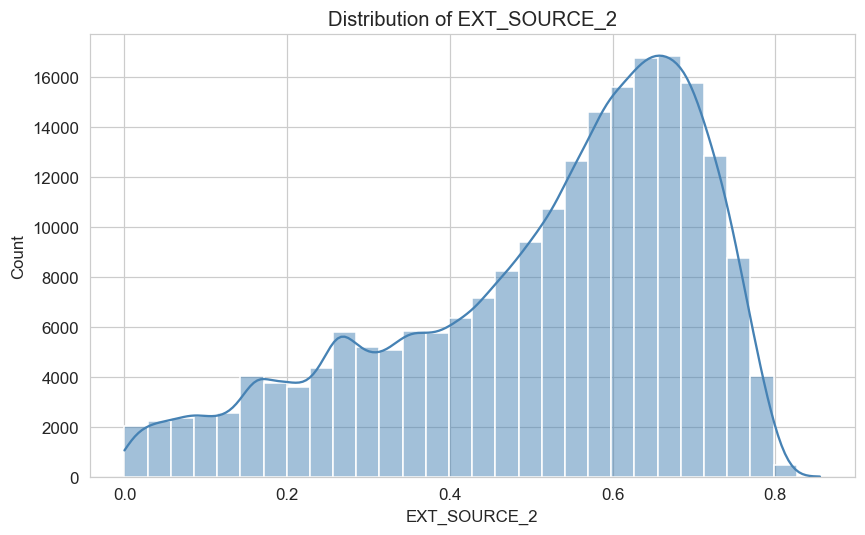

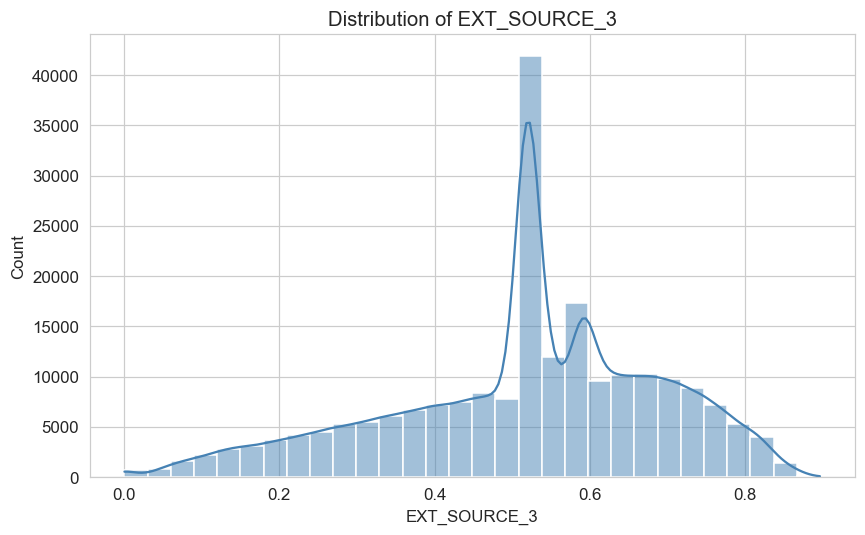

In [9]:
numeric_cols = [
    'age_years', 'annual_income', 'loan_amount', 'annual_repayment',
    'debt_to_income', 'repayment_burden', 'employment_years',
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'
]

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], bins=30, kde=True, color='steelblue')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

## 5. Default rate by category

Very small groups (Businessman, Student, Maternity leave, Unemployed, XNA gender, Unknown family status) have only a handful of borrowers, so their bars are not meaningful.

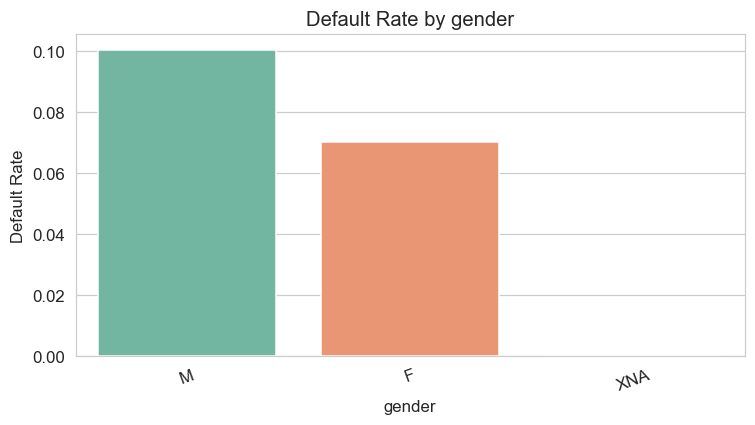

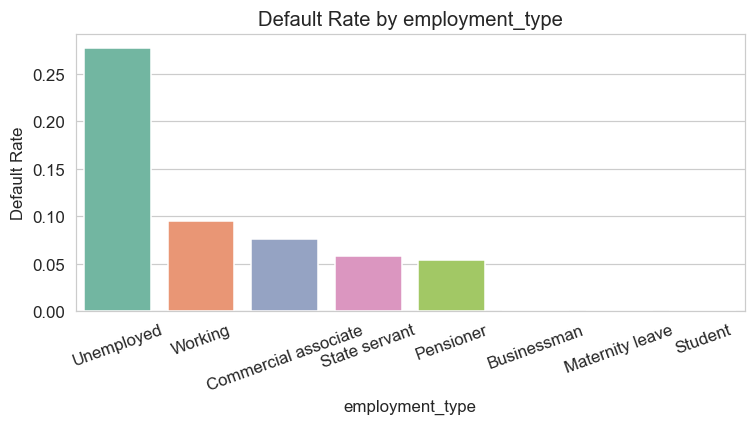

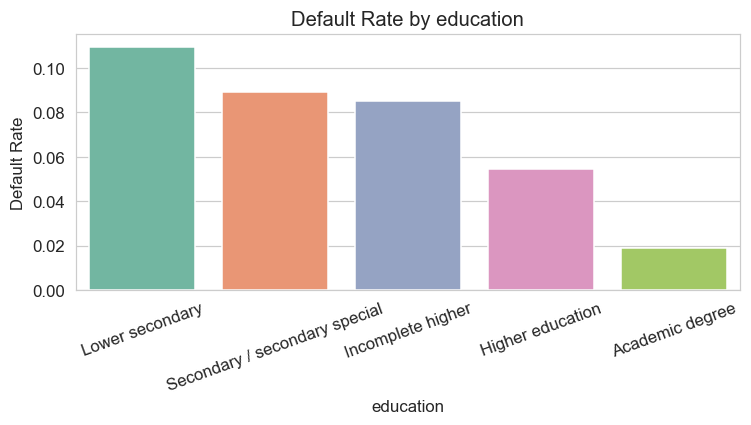

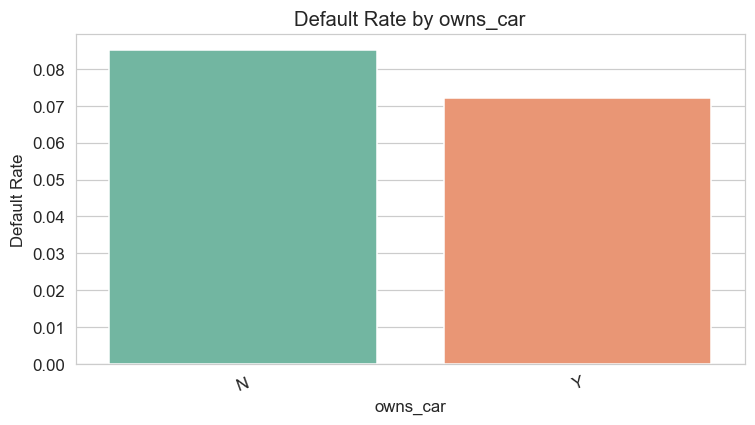

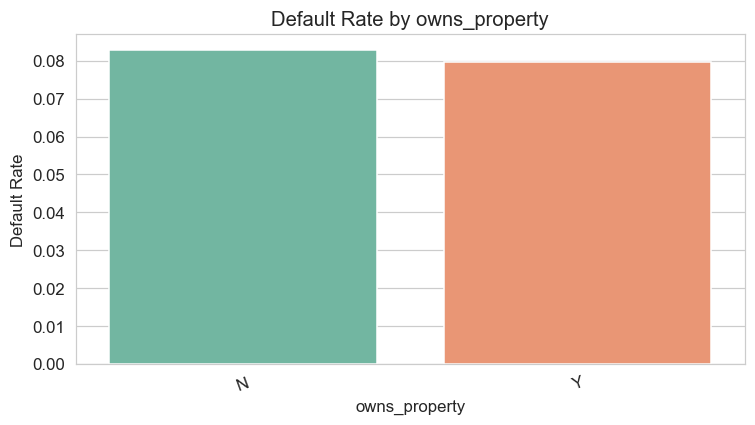

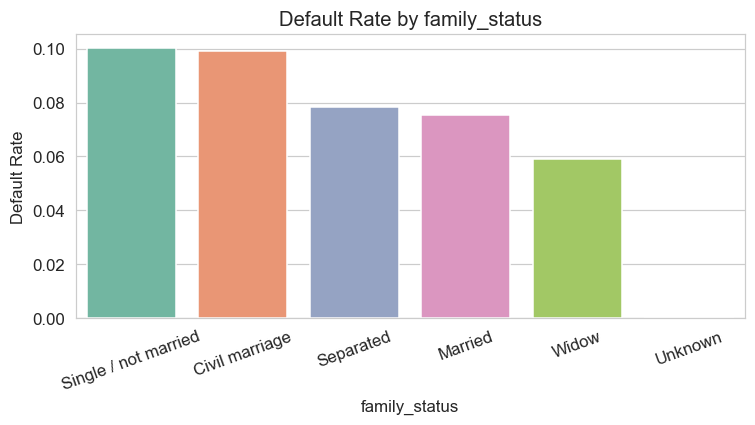

In [11]:
cat_cols = ['gender', 'employment_type', 'education', 'owns_car', 'owns_property', 'family_status']

for col in cat_cols:
    default_rate = df.groupby(col)['TARGET'].mean().sort_values(ascending=False)

    plt.figure(figsize=(7, 4))
    sns.barplot(x=default_rate.index, y=default_rate.values,
                hue=default_rate.index, palette='Set2', legend=False)
    plt.title(f'Default Rate by {col}')
    plt.xlabel(col)
    plt.ylabel("Default Rate")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

## 6. Correlation heatmap

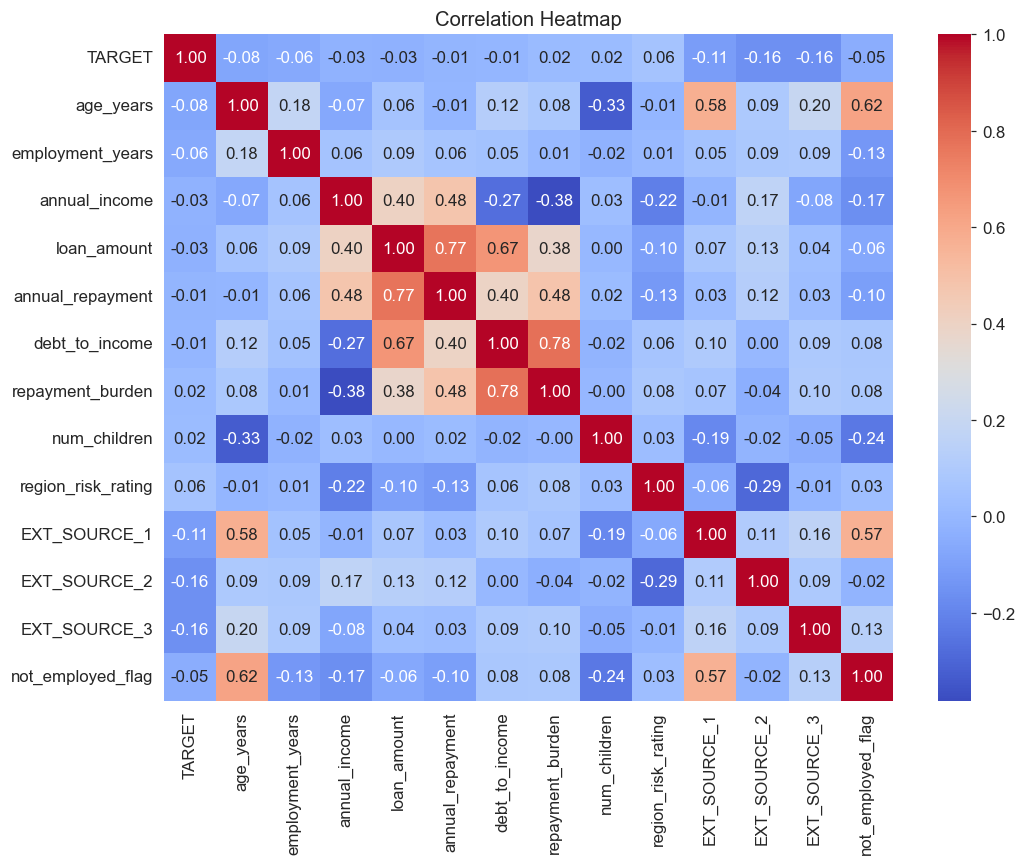

In [13]:
plt.figure(figsize=(10, 8))
corr = df.drop(
    columns=['SK_ID_CURR', 'EXT_SOURCE_1_raw', 'EXT_SOURCE_2_raw', 'EXT_SOURCE_3_raw'],
    errors='ignore'
).corr(numeric_only=True)

sns.heatmap(corr, cmap='coolwarm', annot=True, fmt='.2f')
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()